# Code Ownership, notebook 4: hyperparameter tuning without selection bias

Every encoder x feature set x head is tuned inside each outer training set by 4 inner folds grouped by function; the outer fold's prediction comes from a head refit on the
whole outer training set. Grids are in `helpers/ko_models.py` (fixed before the run). The runner is resumable and takes a while; finished combinations are kept in
`results/tuning_preds.pkl`.

In [1]:
import sys, warnings, json, pickle
from pathlib import Path
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path("../../helpers").resolve()))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import spearmanr
import ko_data as K, ko_models as M
from core import metrics, group_bootstrap, paired_diff_bootstrap, qwk, band
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 90)
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)
d = K.load()
dev = d[d.role == "dev"].reset_index(drop=True)
test = d[d.role == "test"].reset_index(drop=True)
y, groups, folds = dev.score.to_numpy(), dev.snippet_id.to_numpy(), dev.fold.to_numpy()
def ci(p, stat):
    return group_bootstrap(y, p, groups, stat, n=1000)
def sp(a, b):
    return spearmanr(a, b).correlation
def mae(a, b):
    return float(np.mean(np.abs(a - b)))
def rmse(a, b):
    return float(np.sqrt(np.mean((a - b) ** 2)))

In [2]:
import run_tuning
from embedder import Encoder
ENCODERS = [k for k in ("unixcoder", "codebert", "mpnet") if (Encoder._local(k) or k == "mpnet")]
P = run_tuning.run(ENCODERS, workers=10)
print(len(P), "combinations")

144 combinations


In [3]:
rows = []
for key, v in P.items():
    e, s, h = key.split("|"); p = v["pred"]
    rows.append({"encoder": e, "feature set": s, "head": h, "RMSE": rmse(p, y), "MAE": mae(p, y), "Spearman": sp(p, y)})
T = pd.DataFrame(rows)
T.to_csv(RESULTS / "tuning.csv", index=False)
T.pivot_table(index=["encoder", "feature set"], columns="head", values="RMSE").round(3)

head                   boosting  forest  kernel_ridge    mlp  ridge    svr
encoder   feature set                                                     
codebert  A               0.262   0.258         0.260  0.541  0.267  0.267
          A+H             0.225   0.230         0.254  0.509  0.251  0.217
          B               0.263   0.259         0.261  0.509  0.267  0.266
          B+H             0.225   0.230         0.254  0.526  0.251  0.216
          C               0.299   0.291         0.297  0.541  0.266  0.268
          C+H             0.251   0.251         0.296  0.532  0.251  0.223
          D               0.340   0.318         0.269  0.539  0.297  0.285
          D+H             0.250   0.245         0.265  0.504  0.256  0.234
mpnet     A               0.366   0.366         0.352  0.577  0.330  0.335
          A+H             0.281   0.271         0.316  0.539  0.280  0.250
          B               0.364   0.368         0.352  0.578  0.331  0.335
          B+H             0.284   0.276         0.316  0.562  0.280  0.250
          C               0.374   0.368         0.403  0.551  0.334  0.342
          C+H             0.280   0.276         0.380  0.614  0.286  0.254
          D               0.370   0.369         0.374  0.558  0.350  0.356
          D+H             0.274   0.272         0.339  0.539  0.293  0.268
unixcoder A               0.342   0.335         0.308  0.530  0.293  0.279
          A+H             0.273   0.273         0.299  0.507  0.267  0.243
          B               0.339   0.337         0.308  0.560  0.293  0.279
          B+H             0.273   0.274         0.299  0.491  0.267  0.243
          C               0.354   0.352         0.361  0.566  0.304  0.302
          C+H             0.279   0.276         0.353  0.494  0.283  0.258
          D               0.340   0.345         0.361  0.523  0.352  0.349
          D+H             0.269   0.279         0.329  0.512  0.292  0.265

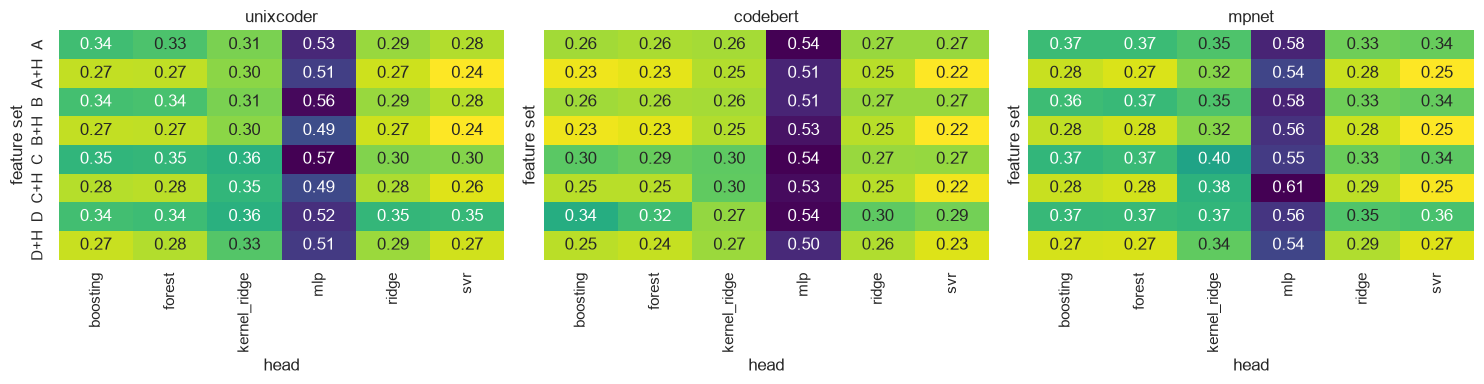

In [4]:
fig, axes = plt.subplots(1, len(ENCODERS), figsize=(5 * len(ENCODERS), 4), sharey=True, squeeze=False)
for ax, e in zip(axes[0], ENCODERS):
    sns.heatmap(T[T.encoder == e].pivot(index="feature set", columns="head", values="RMSE"), annot=True, fmt=".2f", cmap="viridis_r", ax=ax, cbar=False); ax.set_title(e)
plt.tight_layout(); plt.show()

Settings chosen in each outer fold for the ridge heads (stability of the choice):

In [5]:
ch = []
for key, v in P.items():
    e, s, h = key.split("|")
    if h == "ridge":
        ch.append({"encoder": e, "feature set": s, **{f"fold {f}": p["alpha"] for f, p in v["chosen"].items()}})
pd.DataFrame(ch)

,encoder,feature set,fold 0,fold 1,fold 2,fold 3,fold 4
0,mpnet,A,100,1000,1000,1000,1000
1,mpnet,B,100,1000,1000,1000,1000
2,mpnet,C,1000,1000,1000,1000,1000
3,mpnet,D,1000,1000,1000,1000,1000
4,mpnet,A+H,1000,1000,1000,1000,1000
5,mpnet,B+H,1000,1000,1000,1000,1000
6,mpnet,C+H,1000,1000,1000,1000,1000
7,mpnet,D+H,1000,1000,1000,1000,1000
8,unixcoder,A,100,1000,1000,1000,1000
9,unixcoder,B,100,1000,1000,1000,1000


## Reading the results

**What the grid shows (144 combinations: 3 encoders x 8 feature sets x 6 heads).** The best combinations all have the hand-built features appended ("+H") with the weight on that block chosen by the inner folds; without that weight the 12 hand features were drowned by 768 embedding columns (a design flaw found in the first run and corrected before the final test, see the protocol amendment log). Feature set A or B (answer embedding, with or without the three similarities) with an RBF support vector head is best for every encoder. The joint question+answer embedding (D) and the answer-times-reference interaction (C) do not help. The small neural network head fails (best RMSE 0.49 to 0.54; it overfits 178 answers).

**Encoders compared (best combination of each, development MAE).** CodeBERT 0.161, UniXcoder 0.187, mpnet 0.192, hand-built features alone 0.206.
